In [2]:
import matplotlib.cm as cm
import matplotlib.colors as colors
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib as mpl
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
from scipy.stats import mannwhitneyu

In [7]:
tmp_data_save_path = Path('/home/nuo/Documents/data/LeciLab/behavioral_data/tmp/escape/processing_data')
sound_type = ["pink_noise", "looming"]
figure_export_root = Path('/home/nuo/Documents/data/LeciLab/behavioral_data/tmp/escape/looming_pinknoise_comparison')

In [4]:
def _safe_figure_file_stem(text):
    safe_text = "".join(
        char if char.isalnum() or char in {"-", "_", "."} else "_"
        for char in str(text).strip()
    )
    while "__" in safe_text:
        safe_text = safe_text.replace("__", "_")
    safe_text = safe_text.strip("_.")
    return safe_text or "figure"

def save_figures_to_folder(
    figure_items,
    folder_name,
    file_format="svg",
    dpi=300,
):
    figure_folder = figure_export_root / str(folder_name)
    figure_folder.mkdir(parents=True, exist_ok=True)

    saved_paths = []
    file_stem_counts = {}
    for title, fig in figure_items:
        bbox_inches = "tight"
        if not hasattr(fig, "savefig"):
            ax = fig
            fig = ax.figure
            fig.canvas.draw()
            bbox_inches = ax.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())

        file_stem = _safe_figure_file_stem(title)
        file_stem_counts[file_stem] = file_stem_counts.get(file_stem, 0) + 1
        if file_stem_counts[file_stem] > 1:
            file_stem = f"{file_stem}_{file_stem_counts[file_stem]:02d}"

        figure_path = figure_folder / f"{file_stem}.{file_format}"
        fig.savefig(
            figure_path,
            format=file_format,
            dpi=dpi,
            bbox_inches=bbox_inches,
        )
        saved_paths.append(figure_path)

    return saved_paths

In [5]:
pn_leaveSpd_escape_sound_list = pd.read_csv(Path(tmp_data_save_path, f"{sound_type[0]}_sound_escape_leave_speed.csv")).values
lm_leaveSpd_escape_sound_list = pd.read_csv(Path(tmp_data_save_path, f"{sound_type[1]}_sound_escape_leave_speed.csv")).values

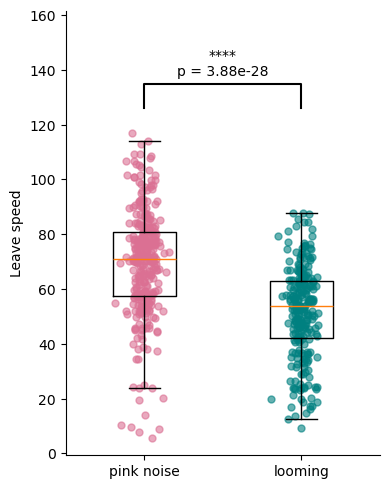

In [8]:


_pn = np.asarray(pn_leaveSpd_escape_sound_list, dtype=float)
_lm = np.asarray(lm_leaveSpd_escape_sound_list, dtype=float)

# 去掉缺失值和无穷值
_pn = _pn[np.isfinite(_pn)]
_lm = _lm[np.isfinite(_lm)]


# 双侧检验
_p = mannwhitneyu(_pn, _lm, alternative="two-sided").pvalue
_stars = "*" * sum(_p < t for t in [0.05, 0.01, 0.001, 0.0001]) or "ns"

_fig, _ax = plt.subplots(figsize=(4, 5))
_ax.boxplot([_pn, _lm], widths=0.4, showfliers=False)

# 叠加每个样本的散点
_rng = np.random.default_rng(0)
for _i, _values, _color in [
    (1, _pn, "palevioletred"),
    (2, _lm, "teal"),
]:
    _ax.scatter(
        _rng.normal(_i, 0.05, len(_values)),
        _values,
        color=_color,
        alpha=0.6,
        s=25,
    )

# 显著性括号
_h = max(np.ptp(np.r_[_pn, _lm]), 1) * 0.08
_y = max(_pn.max(), _lm.max()) + _h

_ax.plot(
    [1, 1, 2, 2],
    [_y, _y + _h, _y + _h, _y],
    color="k",
)
_ax.text(
    1.5, _y + 1.2 * _h,
    f"{_stars}\np = {_p:.3g}",
    ha="center",
    va="bottom",
)

_ax.set_xticks([1, 2], ["pink noise", "looming"])
_ax.set_ylabel("Leave speed")
_ax.set_ylim(top=_y + 4 * _h)
_ax.spines[["top", "right"]].set_visible(False)

_fig.tight_layout()
save_figures_to_folder(
    figure_items = [("all_leave_speed_comparison", _fig)],
    folder_name = "",
    file_format="svg",
    dpi=300,
)
plt.show()

# Daily escape fractions

In [3]:
escape_fraction_dfs = {
    (stimulus, condition): pd.read_csv(
        Path(tmp_data_save_path) / f"{stimulus}_{condition}_escape_fraction.csv",
        index_col="mouse",
    ).reindex(columns=["1", "2", "3", "4"]).apply(pd.to_numeric, errors="coerce")
    for stimulus in ["pinknoise", "looming"]
    for condition in ["sound", "nosound"]
}

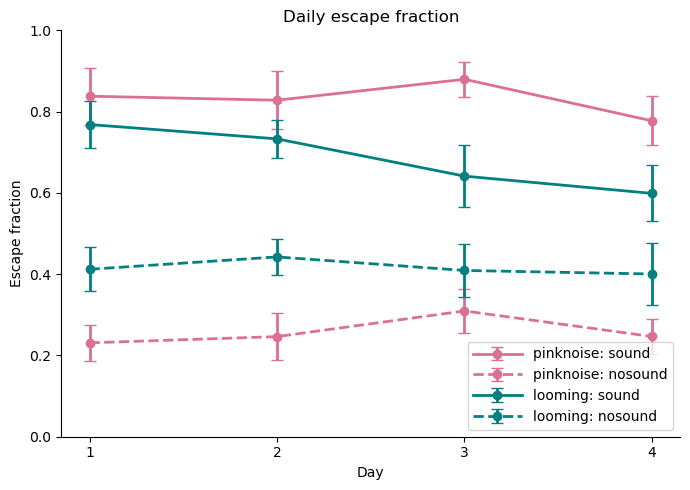

In [16]:
fig, ax = plt.subplots(figsize=(7, 5))
for stimulus, color in [("pinknoise", "palevioletred"), ("looming", "teal")]:
    for condition, linestyle in [("sound", "-"), ("nosound", "--")]:
        values = escape_fraction_dfs[stimulus, condition]
        ax.errorbar(
            [1, 2, 3, 4], values.mean(), yerr=values.sem(),
            color=color, marker="o", linestyle=linestyle,
            linewidth=2, capsize=4, label=f"{stimulus}: {condition}",
        )

ax.set(
    xlabel="Day", ylabel="Escape fraction", xticks=[1, 2, 3, 4],
    ylim=(0, 1), title="Daily escape fraction",
)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(handlelength=3.5)
fig.tight_layout()
fig.savefig(
    Path(output_dir, f"daily_escape_fraction.pdf"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()